# 06_risk：風險清單（驗證期）

設定與協定見 `setup.yaml`；程式在 `src/s06_risk.py`。預設 `RUN = False` 只讀已存的結果。

In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
R = ROOT / "results"
def show(name, n=60):
    p = R / f"{name}.csv"
    display(Markdown(f"**{name}**")); display(pd.read_csv(p, encoding="utf-8-sig").head(n)) if p.exists() else print("缺", name)
def fig(name, w=800):
    p = R / "figures" / name
    display(Image(filename=str(p), width=w)) if p.exists() else print("缺圖", name)

In [2]:
RUN = False
if RUN:
    from src import s06_risk
    s06_risk.main()

**06_val_var**

,狀態,日數,VaR95,CVaR95
0,全部,3122,0.012576,0.024090
1,低波動,1381,0.009401,0.013814
2,中波動,1080,0.011552,0.019081
3,高波動,661,0.026099,0.041190
4,多頭,2459,0.009908,0.016697
5,空頭,663,0.024403,0.039192


**06_val_regime**

,波動,趨勢,日數,年化報酬,Sharpe,MDD（狀態內串接）
0,低波動,多頭,1313,0.127497,1.339175,-0.131343
1,低波動,空頭,68,0.603605,4.233943,-0.040393
2,中波動,多頭,821,0.218382,2.183267,-0.066080
3,中波動,空頭,259,-0.019057,-0.101361,-0.245551
4,高波動,多頭,325,0.162355,0.830959,-0.185009
5,高波動,空頭,336,0.436123,1.376000,-0.311237


**06_val_risk_summary**

,Unnamed: 0,值
0,MDD,-0.3503932861891358
1,高點,2022-03-30
2,谷底,2022-10-13
3,回撤天數（高點→谷底）,135
4,恢復日,2023-12-12
5,恢復天數（谷底→恢復）,282
6,最長水下天數,416
7,全期 beta,0.6551681679191771
8,beta lo,0.5949655053217694
9,beta hi,0.7153708305165848


... (2 outputs left out)

**06_val_killswitch**

,門檻,動作,負責人,首次觸發,觸發天數
0,-10%,watch,研究者本人（期中）,2015-08-19,332
1,-15%,halve,研究者本人（期中）,2015-08-24,191
2,-20%,halt_new_entries,研究者本人（期中）,2020-03-19,86
3,-25%,unwind,研究者本人（期中）,2022-07-12,35


**06_risk_matrix**

,風險,代理指標,控制,頻率
0,市場,滾動 120 日 beta（對 0050）,beta > 1.3 持續 60 日 → 檢查是否集中在高 beta 股,每週
1,因子,持股的 vol60、adv60 平均排名,偏離可投資池中位數 0.3 以上 → 列入檢討,每次檢視
2,槓桿,總曝險 = 持股市值 / 淨值,上限 1.0（模擬內強制）,每日
3,集中度,單檔權重、1/HHI,單檔 ≤ 10%（模擬內強制）；1/HHI < 12 警示,每次檢視
4,流動性,持股金額 / 20 日均成交額,"> 5% 不進場；可投資池門檻 2,000 萬",每次檢視
5,模型,30/60/90 日滾動 IC、PSI,60 日 IC < 0 且 PSI > 0.25 → 重訓；90 日 IC < 0 → 暫停,每週
6,營運,資料下載檢查（檔數、殘缺日）、執行對帳,當日檔數 < 前 60 日中位數一半 → 不下單,每日


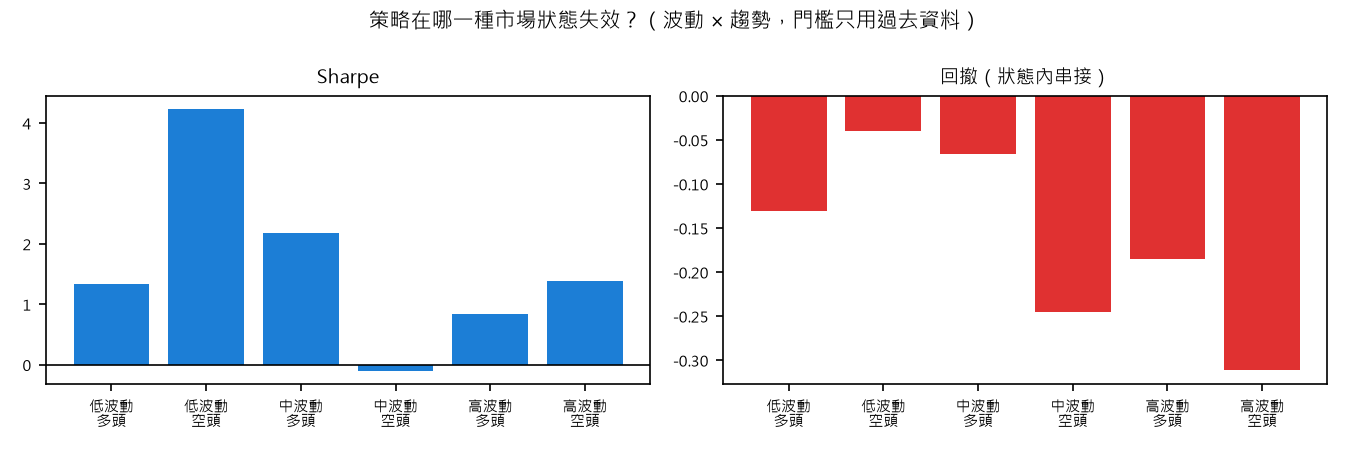

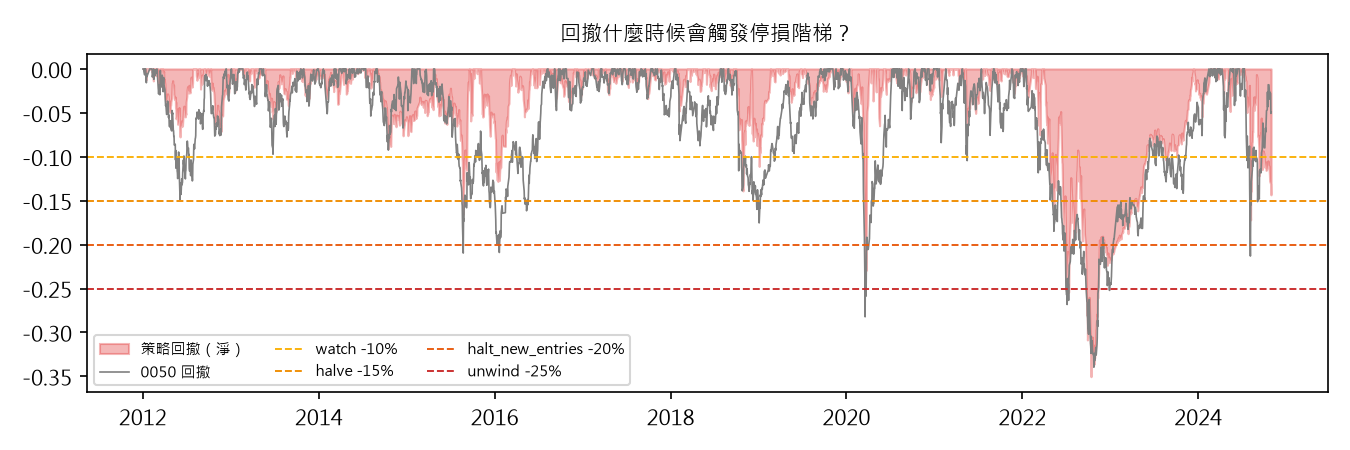

In [3]:
for t in ("var", "regime", "risk_summary", "stress", "killswitch"): show(f"06_val_{t}")
show("06_risk_matrix")
fig("06_val_regime.png"); fig("06_val_drawdown.png")